# 01 · Methodology checks

Before modelling, we test some common pitfalls in regression projects on this data, to see how much each would distort the results and to justify the protocol used in 02–06.

| # | Pitfall | What happens on this data | Decision |
|---|---|---|---|
| 1 | z-score outlier removal on all columns | Deletes **every** player worth ≥ €50M | Keep all players; model log(value) |
| 2 | OLS without an intercept | Reports *uncentered* R², which looks better than it is | Always include an intercept |
| 3 | Scoring a log model's RMSE against euros | The number is meaningless | Compare models on a common scale |
| 4 | Fitting on all rows, then scoring a subset | Leakage | Out-of-fold predictions only |
| 5 | Ranking models on one random split | Rankings within split noise | 5-fold CV, same folds for all |
| 6 | Raw-€ OLS inference on pooled roles | Heteroscedastic, mixed populations | Log target, HC3, per-role models (05) |

In [1]:
import warnings

import numpy as np
import pandas as pd
import statsmodels.api as sm
from scipy import stats
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

warnings.filterwarnings("ignore")
d = pd.read_csv("../data/player_stats_clean.csv")
rmse = lambda a, b: np.sqrt(mean_squared_error(a, b))
num_cols = [c for c in d.select_dtypes("number").columns if c not in ("value", "value_m", "log_value", "is_gk")]

## 1. z-score outlier removal deletes the players that matter most

In [2]:
frame = d[num_cols + ["value_m"]]
kept = frame[(np.abs(stats.zscore(frame)) < 4).all(axis=1)]
dropped = d.loc[~d.index.isin(kept.index)]
print(f"|z| < 4 filter: {len(frame)} → {len(kept)} rows")
print(f"Players worth ≥ €50M: {(d.value_m >= 50).sum()} in data, {(dropped.value_m >= 50).sum()} removed")
dropped.nlargest(10, "value_m")[["player", "club", "age", "value_m"]]

|z| < 4 filter: 5677 → 5615 rows
Players worth ≥ €50M: 25 in data, 25 removed


,player,club,age,value_m
5226,Kylian Mbappé,Paris SG,24,153.5
1962,Erling Haaland,Manchester City,23,123.0
4846,Kevin De Bruyne,Manchester City,32,107.5
913,Sadio Mané,FC Bayern München,31,101.0
5673,Mohamed Salah,Liverpool,31,99.5
5674,Neymar Jr,Paris SG,31,99.5
5133,Joshua Kimmich,FC Bayern München,28,97.0
4208,Virgil van Dijk,Liverpool,32,84.5
3413,Lautaro Martínez,Inter,26,79.5
2455,Gianluigi Donnarumma,Paris SG,24,78.0


Removing high-leverage points because they are inconvenient is not outlier treatment. These are valid observations in the tail of a log-normal distribution. On the log scale (used from 02 onwards) they are not outliers at all:

In [3]:
print("players with |z| ≥ 4 on log(value):", (np.abs(stats.zscore(d.log_value)) >= 4).sum())

players with |z| ≥ 4 on log(value): 0


## 2. No intercept → uncentered R²

In [4]:
X, y = d[num_cols], d.value_m
pd.DataFrame(
    {"no intercept (uncentered R²)": [sm.OLS(y, X).fit().rsquared, sm.OLS(np.log(y), X).fit().rsquared],
     "with intercept (proper R²)": [sm.OLS(y, sm.add_constant(X)).fit().rsquared,
                                    sm.OLS(np.log(y), sm.add_constant(X)).fit().rsquared]},
    index=["OLS on value", "OLS on log(value)"]).round(3)

,no intercept (uncentered R²),with intercept (proper R²)
OLS on value,0.368,0.300
OLS on log(value),0.807,0.822


Without a constant, statsmodels measures R² against **zero** instead of the mean, so the number is not comparable with an ordinary R².

## 3. Comparing a log model's error on the wrong scale

In [5]:
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.3, random_state=42)
log_model = sm.OLS(np.log(y_tr), sm.add_constant(X_tr)).fit()
p_log = log_model.predict(sm.add_constant(X_te))
print("RMSE(value, predicted LOG value)  [wrong]  :", round(rmse(y_te, p_log), 3))
print("RMSE(value, exp(predicted log))   [correct]:", round(rmse(y_te, np.exp(p_log)), 3))

RMSE(value, predicted LOG value)  [wrong]  : 6.873
RMSE(value, exp(predicted log))   [correct]: 4.638


Comparing a prediction of log(value) with value in euros produces a number with no meaning, and it can make log or Box-Cox models look worse than they are. Even done correctly, RMSE in euros is dominated by a few superstars, so 02 compares models on % error and on the log scale.

## 4. Leakage: fit on all rows, score on a subset of them

In [6]:
leak = Ridge(alpha=1.0).fit(X, y)
ok = Ridge(alpha=1.0).fit(X_tr, y_tr)
pd.DataFrame({"test RMSE": [rmse(y_te, leak.predict(X_te)), rmse(y_te, ok.predict(X_te))],
              "test R²": [r2_score(y_te, leak.predict(X_te)), r2_score(y_te, ok.predict(X_te))]},
             index=["Ridge fit on ALL rows", "Ridge fit on train only"]).round(3)

,test RMSE,test R²
Ridge fit on ALL rows,5.717,0.312
Ridge fit on train only,5.773,0.299


For a ~36-coefficient linear model on ~5.7k rows the optimism is small. The procedure is still invalid, and the same mistake with a flexible model, feature selection or PCA can inflate results a lot. From 02 onwards every number is **out-of-fold**.

## 5. One random split cannot rank models

Random Forest test R² (€) over 20 splits: mean 0.818, min 0.727, max 0.879


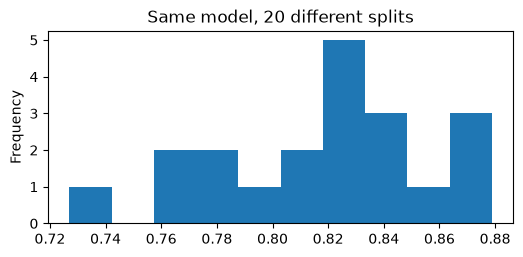

In [7]:
r2s = pd.Series([r2_score(e, RandomForestRegressor(n_estimators=100, random_state=0, n_jobs=-1).fit(a, c).predict(b))
                 for a, b, c, e in (train_test_split(X, y, test_size=0.3, random_state=s) for s in range(20))])
print(f"Random Forest test R² (€) over 20 splits: mean {r2s.mean():.3f}, min {r2s.min():.3f}, max {r2s.max():.3f}")
r2s.plot.hist(bins=10, figsize=(6, 2.5), title="Same model, 20 different splits");

The same model's score moves by several hundredths with the split alone, which is larger than the gap between many competing models. 02 uses 5-fold CV with identical folds for every model.

## 6. Inference on raw euros, pooled across roles

In [8]:
print("dribbling vs ball_control correlation:", round(d[["dribbling", "ball_control"]].corr().iloc[0, 1], 3))
ols_raw = sm.OLS(d.value_m, sm.add_constant(d[["dribbling", "vision", "att_position", "ball_control", "reactions"]])).fit()
print("Breusch-Pagan p-value (raw € OLS):", f"{sm.stats.diagnostic.het_breuschpagan(ols_raw.resid, ols_raw.model.exog)[1]:.1e}")
print(f"Goalkeepers: {d.is_gk.sum()} of {len(d)} players ({d.is_gk.mean():.0%})")

dribbling vs ball_control correlation: 0.947
Breusch-Pagan p-value (raw € OLS): 1.2e-47
Goalkeepers: 632 of 5677 players (11%)


* Raw-euro residuals are strongly heteroscedastic, so classical t/F p-values are unreliable. 05 uses a log target with HC3 robust errors.
* Attribute pairs such as dribbling and ball control are almost collinear, so individual t-tests have little power. 05 adds VIFs and joint tests.
* Goalkeepers are only 11% of players. A "goalkeeper attributes" model fit on everyone mostly measures outfielders, whose GK stats are noise. 05 fits each role on its own players and corrects for multiple testing (Benjamini–Hochberg).